# 0. Setup (Layered architecture)

## Install Neccersary Packages

The following packages are needed for the program:

* `ipywidgets`: For UI
* `mne`: For data processing
* `numpy`
* `python-picard`: Specific method for ICA during Preprocessing



In [1]:
%pip install ipywidgets
%pip install mne
%pip install numpy matplotlib scipy
%pip install python-picard
%pip install pandas 
%pip install xlrd openpyxl
%pip install pylsl 



Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


...


[notice] A new release of pip is available: 24.3.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## UI

Building the UI utilising `ipywidgets`

In [2]:
from ipywidgets import interact, Dropdown, Text, VBox, HBox, Checkbox, IntSlider

fileUpload = Text(value='data.bdf', description='File Path:')
labelUpload = Text(value='participant_ratings.xls', description='File Path:')
downsampleOnOff = Checkbox(value=True, description='Downsample')
downsampleDropdown = Dropdown(options=['128', '256', '512'], value='128', description='Downsample Rate:')
bandpassOnOff = Checkbox(value=True, description='Bandpass Filter')
icaMethod = Dropdown(options=['fastica', 'infomax', 'picard'], value='picard', description='ICA Method:')
icaOnOff = Checkbox(value=False, description='ICA')
fastICA = Checkbox(value=True, description='ICA after Downsample')


ui = VBox([
    HBox([fileUpload, labelUpload]),
    HBox([downsampleOnOff, downsampleDropdown]),
    bandpassOnOff,
    HBox([icaOnOff,fastICA, icaMethod])
])

# things to add: FastICA (done after downsample)

In [3]:
display(ui)

# 1. Classes

In [4]:
import mne
import pandas as pd
from scipy.signal import decimate
from scipy.fft import rfft, rfftfreq
import numpy as np
from tqdm.auto import tqdm

RANDSEED = 52

### 1.1 Dataloader

In [15]:
class Dataloader:
  def __init__(self):
    self.muse_map = {
              'TP9': 'P7',    # left temporal
              'AF7': 'F3',    # left frontal
              'AF8': 'F4',    # right frontal
              'TP10': 'P8',   # right temporal
              
          }
  def getData(self, fileUpload):
    raw = mne.io.read_raw_bdf(fileUpload, preload=True)
    
    # deap_channels = list(self.muse_map.values()) + ['Status']
    # rawcopy = raw.copy().pick(deap_channels)

    rawcopy = raw.copy().pick([ch for ch in raw.ch_names if ch.startswith(("Fp","F","C","P","O","T","Status"))] )    
    events = mne.find_events(raw, stim_channel="Status", initial_event=True) #events comes as 3 columnes (sample Index, prev event code, event code), these are used for segmenting
    return rawcopy, events

  def getLabels(self, labelUpload, particpant):
    df = pd.read_excel(labelUpload)
    valencedf = df[['Participant_id','Valence']]
    valence = valencedf[valencedf['Participant_id'] == particpant]    #just getting the first particpant while testing
    return valence


### 1.2 Preprocess

In [16]:
class Preprocessing:
    def __init__(self, icaMethod, randSeed, nComponents = 0.999999):
        # self.ica = mne.preprocessing.ICA(nComponents, random_state=randSeed, max_iter='auto', method = icaMethod.value)
        self.randSeed = randSeed
        self.icaMethod = icaMethod.value
        
    def preprocess(self, raw, downsampleTrue, downsamplerate, bandpassTrue, icaTrue, icaMethod,fastICA, events):
        rawCopy = raw.copy()
        
        #highpass:
        rawCopy = rawCopy.filter(l_freq=1.5, h_freq=None)
        
        #Downsample:
        if(downsampleTrue == True):
            rawCopy = rawCopy.resample(sfreq=int(downsamplerate))
        
        #ICA:
        if(icaTrue == True):
            self.ica = mne.preprocessing.ICA(method=self.icaMethod, random_state=self.randSeed, max_iter='auto')
            self.ica.fit(rawCopy)
            eog_chs = [ch for ch in ['Fp1','Fp2'] if ch in rawCopy.ch_names]
            
            if eog_chs:
                eogArtifacts, _ = self.ica.find_bads_eog(rawCopy, ch_name=eog_chs)
            else:
                eogArtifacts = []  
                
            muscleArtifacts, _ = self.ica.find_bads_muscle(rawCopy)
            
            exclude = (eogArtifacts or []) + (muscleArtifacts or [])
            exclude = [i for i in exclude if i < self.ica.n_components_]
            self.ica.exclude = exclude
            
            rawCopy = self.ica.apply(rawCopy.copy())
        
        #bandpass
        if(bandpassTrue == True):
            rawCopy = rawCopy.filter(l_freq=4, h_freq=45)
            
        return rawCopy
        


### 1.3 Segmentation

In [17]:
class Segmentation:
    def __init__(self, window_size=4.0, overlap=0.75):
        """
        window_size : length of each epoch in seconds
        overlap     : fraction overlap between windows (0.0–0.9)
        """
        self.window_size = window_size
        self.overlap = overlap

    def getEpochs(self, raw, events, eventId, labels):
        """
        raw      : preprocessed MNE Raw
        events   : DEAP event markers
        eventId  : event code to use for trial onset (e.g. {4: 'video'})
        labels   : np.array of labels (40 per participant)

        Returns:
          X_epochs : (n_epochs, n_channels, n_samples)
          y_labels : (n_epochs,)
        """
        sfreq = raw.info['sfreq']
        win_samp = int(self.window_size * sfreq)
        step_samp = int(win_samp * (1 - self.overlap))

        # Make 60s epochs first (just to anchor each video trial)
        tmin, tmax = 0, 60
        epochs = mne.Epochs(raw, events, event_id={'video': eventId}, tmin=tmin, tmax=tmax,
                            baseline=None, preload=True)
        epochs = epochs.drop_channels(["Status"])
        data = epochs.get_data()   # shape (n_trials, n_channels, n_samples)
        print(f"Epoch Shapeeeeeeeeeeeee: {epochs.get_data().shape[1]}")
        X_segments, y_segments = [], []

        for trial_idx, trial_data in enumerate(data):
            label = labels[trial_idx]

            n_samples = trial_data.shape[-1]
            start = int(3 * sfreq)  # skip first 3s
            end = n_samples

            # Sliding windows inside this trial
            for s in range(start, end - win_samp + 1, step_samp):
                seg = trial_data[:, s:s+win_samp]  # (n_channels, win_samp)
                X_segments.append(seg)
                y_segments.append(label)

        return np.array(X_segments), np.array(y_segments)

### 1.4 Feature Extraction


In [18]:
class FeatureExtraction:
    def __init__(self):
        self.bands = {
            'delta': (0.5, 4),
            'theta': (4, 7),
            'alpha': (7, 12),
            'beta':  (12, 30),
            'gamma': (30, 45),
        }

    def fftBandPowers(self, seg, samplingRate):
        """
        seg: (n_channels, n_samples) single window
        """
        yf = np.abs(rfft(seg, axis=-1)) ** 2
        xf = rfftfreq(seg.shape[-1], 1 / samplingRate)

        features = [np.sum(yf[:, (xf >= low) & (xf <= high)], axis=-1)
                    for low, high in self.bands.values()]
        features = np.array(features)  
        features = np.log(features + 1e-8)

        return np.concatenate(features, axis=-1)  # (n_channels * n_bands,)

    def extract(self, segments, labels, samplingRate):
        """
        segments : (n_epochs, n_channels, n_samples)
        labels   : (n_epochs,)
        """
        
        X = [self.fftBandPowers(seg, samplingRate) for seg in segments]
        X = np.stack(X, axis=0)
        return X, labels

#2. Pipeline

### 2.1 Constructors


In [19]:
dl = Dataloader()
preProcessor = Preprocessing(randSeed = RANDSEED, nComponents = 0.999, icaMethod = icaMethod)
segmenter = Segmentation(window_size=4.0, overlap=0.75)
fE = FeatureExtraction()


### 2.2 Dataflow

  0%|          | 0/2 [00:00<?, ?it/s]

Extracting EDF parameters from c:\Users\kianc\Desktop\UNI\Comp4092 Thesis\Local Code\s01.bdf...
BDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1980927  =      0.000 ...  3868.998 secs...
Finding events on: Status
13761 events found on stim channel Status
Event IDs: [    1     2     3     4     5     6     7 65536]
[Dataloader] Raw shape: (33, 1980928), sfreq: 512.0


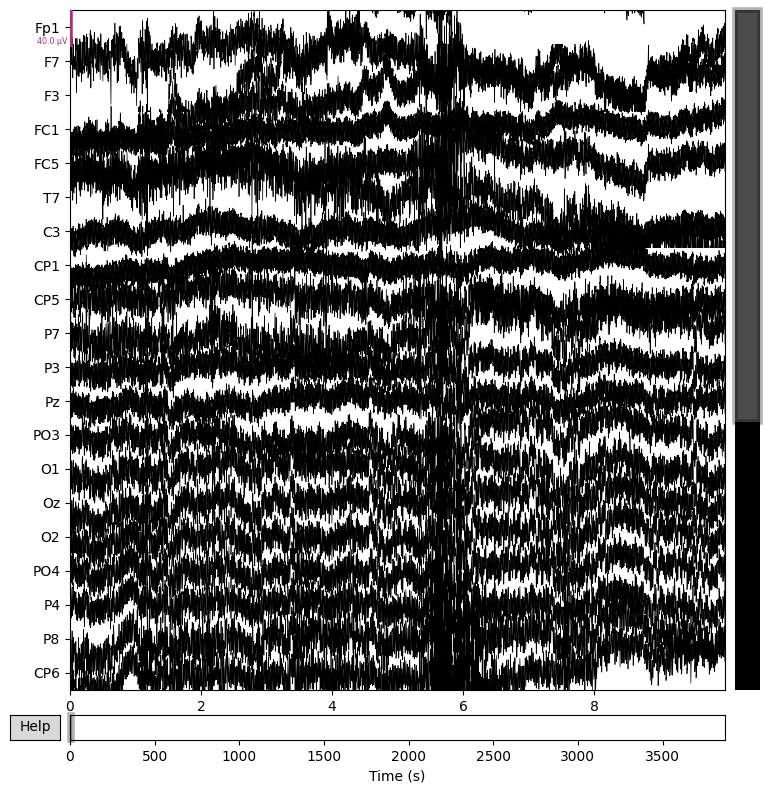

Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.50
- Lower transition bandwidth: 1.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 1127 samples (2.201 s)

Finding events on: Status
Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
13760 events found on stim channel Status
Event IDs: [1 2 3 4 5 6 7]
Finding events on: Status
Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
11519 events found on stim channel Status
Event IDs: [1 2 3 4 5 6 7]
Fitting ICA t

C:\Users\kianc\AppData\Local\Temp\ipykernel_15772\4279343142.py:15: RuntimeWarning: Resampling of the stim channels caused event information to become unreliable. Consider finding events on the original data and passing the event matrix as a parameter.
  rawCopy = rawCopy.resample(sfreq=int(downsamplerate))


Selecting by non-zero PCA components: 21 components


In [20]:
allX = []
allYLabels = []
participants  = []

for i in tqdm(range(1, 3)):  # participants 1 to 22
  fileUpload = f"s{i:02d}.bdf"
  raw, events = dl.getData(fileUpload) # events is shape (13761, 3), df is (1980928, 34)

  print(f"[Dataloader] Raw shape: {raw.get_data().shape}, sfreq: {raw.info['sfreq']}")
  labels = dl.getLabels(labelUpload.value, particpant = i) # labels are (particpant id, valence float score from 1 - 9) 40 values for 40 videos
  raw.plot()
  praw = preProcessor.preprocess(raw = raw,  #(495232, 33)
                                    downsampleTrue = downsampleOnOff.value,
                                    downsamplerate = downsampleDropdown.value,
                                    bandpassTrue = bandpassOnOff.value,
                                    icaTrue = icaOnOff.value,
                                    icaMethod = icaMethod,
                                    fastICA = fastICA.value,
                                    events = events)
  praw.plot()

  # epochs = segmenter.getEpochs(raw = praw, eventId= 4, labels = labels) #shape is like (num of epochs, channels, time sample for each channel)
  X_segments, y_segments = segmenter.getEpochs(
    raw=praw,
    events=events,
    eventId=4,
    labels=labels['Valence'].to_numpy()
  )

  # X, xTime, ylabels = fE.extract(segments = epochs, labels = labels['Valence'].to_numpy(), samplingRate = praw.info['sfreq'])
  X, ylabels = fE.extract(X_segments, y_segments, praw.info['sfreq'])

  allX.append(X)
  allYLabels.append(ylabels)
  participants.extend([i] * len(ylabels))
  print(f"Sanity Check: {X.shape}")

for i, X in enumerate(allX):
    print(f"[Concat Check] Participant {i}: {X.shape}")
allX = np.vstack(allX)
allYLabels = np.hstack(allYLabels)

In [ ]:
ylabels


In [ ]:
import pickle
with open("RawData22", 'rb') as f:
    rawX = pickle.load(allX)
    rawY = pickle.load(allYLabels)

In [7]:
allX, allYLabels, participants = [],[],[]
import pickle
with open("158ICAFastICA", 'rb') as f:
    allX = pickle.load(f)
    allYLabels = pickle.load(f)
    participants = pickle.load(f)

In [31]:
import pickle
with open("158ICAFastICA", 'wb') as f:
    pickle.dump(allX,f)
    pickle.dump(allYLabels,f)
    pickle.dump(participants,f)


In [ ]:
import pickle
with open("RawData22", 'wb') as f:
    pickle.dump(allX,f)
    pickle.dump(allYLabels,f)

In [ ]:
allYLabels

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.utils import shuffle
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# pca = PCA(n_components=0.95)  # keep 95% variance
# X_pca = pca.fit_transform(allX)

y_discrete = (allYLabels >= 5).astype(int)

lda = LDA(n_components=1)
X_lda = lda.fit_transform(allX, y_discrete)

X_lda, y_discrete = shuffle(X_lda, y_discrete, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X_lda, y_discrete, test_size=0.2, random_state=42)

scalar = StandardScaler()
X_train = scalar.fit_transform(X_train)
X_test = scalar.transform(X_test)

svm_clf = SVC(C=10, kernel='linear', gamma='scale')

svm_clf.fit(X_train, y_train)

y_pred = svm_clf.predict(X_test)

acc = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred) # binary classification
f1 = f1_score(y_test, y_pred) # for binary classification
report = classification_report(y_test, y_pred)

print(f"SVM: Accuracy: {acc:.4f}%, Recall :{recall:.4f}%, F1: {f1:.4f}%")
# print(f"Test Accuracy: {acc:.4f}%")

In [13]:
from sklearn.neighbors import KNeighborsClassifier # or KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler # For data scaling
from sklearn.metrics import accuracy_score, recall_score, f1_score, classification_report

y_discrete = (allYLabels >= 5).astype(int)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(allX, y_discrete, test_size=0.3, random_state=42)

# Scale the data (important for distance-based algorithms like KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=2)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

kaccuracy = accuracy_score(y_test, y_pred)
krecall = recall_score(y_test, y_pred) # binary classification
kf1 = f1_score(y_test, y_pred) # for binary classification
kreport = classification_report(y_test, y_pred)

print(f"KNN: Accuracy: {kaccuracy:.4f}%, Recall :{krecall:.4f}%, F1: {kf1:.4f}%")
# print(f"Model Accuracy: {accuracy}")

KNN: Accuracy: 0.7965%, Recall :0.6893%, F1: 0.7859%


In [ ]:
from sklearn.ensemble import RandomForestClassifier
np.unique(y_discrete, return_counts=True)

# Initialize
rf_clf = RandomForestClassifier(
    n_estimators=100,      # number of trees
    max_depth=10,        # let trees grow fully
    random_state=42,
    n_jobs=-1              # use all CPU cores
)

# Train
rf_clf.fit(X_train, y_train)

# Predict
y_pred_rf = rf_clf.predict(X_test)

# Evaluate
rfaccuracy = accuracy_score(y_test, y_pred_rf)
rfrecall = recall_score(y_test, y_pred_rf) # binary classification
rff1 = f1_score(y_test, y_pred_rf) # for binary classification

print(f"RFC: Accuracy: {rfaccuracy:.4f}%, Recall :{rfrecall:.4f}%, F1: {rff1:.4f}%")

# 3. Results

# 4. Testing

In [ ]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score, classification_report
import numpy as np

# Assuming you already have:
# allX  -> concatenated feature matrix (n_epochs_total × n_features)
# allYLabels -> original continuous labels
# groups -> array of participant IDs, same length as allYLabels

y_discrete = (allYLabels >= 5).astype(int)

logo = LeaveOneGroupOut()

accuracies, recalls, f1s = [], [], []

for train_idx, test_idx in tqdm(logo.split(allX, y_discrete, groups=participants)):
    X_train, X_test = allX[train_idx], allX[test_idx]
    y_train, y_test = y_discrete[train_idx], y_discrete[test_idx]

    # Standardize (fit only on train)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Train model
    clf = SVC(C=10, kernel='rbf', gamma='scale')
    clf.fit(X_train, y_train)

    # Evaluate
    y_pred = clf.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))
    recalls.append(recall_score(y_test, y_pred))
    f1s.append(f1_score(y_test, y_pred))

# Report mean ± std across participants
print(f"LOSO Accuracy: {np.mean(accuracies):.4f} ± {np.std(accuracies):.4f}")
print(f"LOSO Recall:   {np.mean(recalls):.4f} ± {np.std(recalls):.4f}")
print(f"LOSO F1:       {np.mean(f1s):.4f} ± {np.std(f1s):.4f}")

#Raw
#LOSO Accuracy: 0.2785 ± 0.3908
# LOSO Recall:   0.0429 ± 0.1966
# LOSO F1:       0.0441 ± 0.2023

#256ICA
# LOSO Accuracy: 0.2716 ± 0.3826
# LOSO Recall:   0.0440 ± 0.1982
# LOSO F1:       0.0458 ± 0.2030

# 256FICA fixed code
# LOSO Accuracy: 0.3036 ± 0.3462
# LOSO Recall:   0.0800 ± 0.2099
# LOSO F1:       0.1017 ± 0.2424

#RAW Fixed:
# LOSO Accuracy: 0.4785 ± 0.0981
# LOSO Recall:   0.1742 ± 0.1921
# LOSO F1:       0.2515 ± 0.2764

# 256FICA fixed code, small epochs
# LOSO Accuracy: 0.4632 ± 0.0606
# LOSO Recall:   0.6602 ± 0.2347
# LOSO F1:       0.5480 ± 0.1083

# 256FICA fixed code, small epochs, pca, fixed ICA, rbf,  
# LOSO Accuracy: 0.5536 ± 0.1028
# LOSO Recall:   0.9103 ± 0.2496
# LOSO F1:       0.6569 ± 0.1872

# 256FICA fixed code, small epochs, lda, fixed ICA, Linear,  
# 256FICA fixed code, small epochs, lda, fixed ICA, Linear,  
# LOSO Accuracy: 0.5413 ± 0.1006
# LOSO Recall:   0.9639 ± 0.0157
# LOSO F1:       0.6903 ± 0.0898

#updated preprocess pipiline, loging the features
# LOSO Accuracy: 0.5244 ± 0.0759
# LOSO Recall:   0.7367 ± 0.2762
# LOSO F1:       0.5914 ± 0.1749

##updated preprocess pipiline, Not loging the features
# LOSO Accuracy: 0.5452 ± 0.1082
# LOSO Recall:   0.8823 ± 0.2672
# LOSO F1:       0.6397 ± 0.2017

#updated preprocess pipiline, loging the features, 0.75 sliding window
# LOSO Accuracy: 0.5231 ± 0.0781
# LOSO Recall:   0.7151 ± 0.2866
# LOSO F1:       0.5815 ± 0.1767

#256, ICA set to Picard





In [ ]:
# from sklearn.model_selection import LeaveOneGroupOut
# from sklearn.preprocessing import StandardScaler
# from sklearn.svm import SVC
# from sklearn.metrics import accuracy_score, recall_score, f1_score, classification_report
# import numpy as np

# # Assuming you already have:
# # allX  -> concatenated feature matrix (n_epochs_total × n_features)
# # allYLabels -> original continuous labels
# # groups -> array of participant IDs, same length as allYLabels

# y_discrete = (allYLabels >= 5).astype(int)

# logo = LeaveOneGroupOut()

# accuracies, recalls, f1s = [], [], []

# for train_idx, test_idx in tqdm(logo.split(allX, y_discrete, groups=participants)):
#     X_train, X_test = allX[train_idx], allX[test_idx]
#     y_train, y_test = y_discrete[train_idx], y_discrete[test_idx]

#     # Standardize (fit only on train)
#     scaler = StandardScaler()
#     X_train = scaler.fit_transform(X_train)
#     X_test = scaler.transform(X_test)

#     # Train model
#     clf = SVC(C=10, kernel='rbf', gamma='scale')
#     clf.fit(X_train, y_train)

#     # Evaluate
#     y_pred = clf.predict(X_test)
#     accuracies.append(accuracy_score(y_test, y_pred))
#     recalls.append(recall_score(y_test, y_pred))
#     f1s.append(f1_score(y_test, y_pred))

# # Report mean ± std across participants
# print(f"LOSO Accuracy: {np.mean(accuracies):.4f} ± {np.std(accuracies):.4f}")
# print(f"LOSO Recall:   {np.mean(recalls):.4f} ± {np.std(recalls):.4f}")
# print(f"LOSO F1:       {np.mean(f1s):.4f} ± {np.std(f1s):.4f}")

# #Raw
# #LOSO Accuracy: 0.2785 ± 0.3908
# # LOSO Recall:   0.0429 ± 0.1966
# # LOSO F1:       0.0441 ± 0.2023

# #256ICA
# # LOSO Accuracy: 0.2716 ± 0.3826
# # LOSO Recall:   0.0440 ± 0.1982
# # LOSO F1:       0.0458 ± 0.2030

# # 256FICA fixed code
# # LOSO Accuracy: 0.3036 ± 0.3462
# # LOSO Recall:   0.0800 ± 0.2099
# # LOSO F1:       0.1017 ± 0.2424

# #RAW Fixed:
# # LOSO Accuracy: 0.4785 ± 0.0981
# # LOSO Recall:   0.1742 ± 0.1921
# # LOSO F1:       0.2515 ± 0.2764

In [ ]:
%pip install  --upgrade pylsl



In [14]:
from pylsl import StreamInlet, resolve_streams
import numpy as np
from scipy.fft import rfft, rfftfreq

# --- Resolve EEG streams ---
print("Looking for EEG streams...")
streams = resolve_streams(5)  # wait 5 seconds for streams
eeg_stream = None
for s in streams:
    if s.type() == 'EEG':
        eeg_stream = s
        break

if eeg_stream is None:
    raise RuntimeError("No EEG stream found!")

# --- Create inlet ---
inlet = StreamInlet(eeg_stream)
print(f"Connected to EEG stream: {eeg_stream.name()}")


Looking for EEG streams...
Connected to EEG stream: Muse-C486 (00:55:da:b7:c4:86) EEG


In [15]:
sfreq = 256          # replace with your Muse sampling rate
window_size = 4.0    # seconds
overlap = 0.5

win_samples = int(window_size * sfreq)
step_samples = int(win_samples * (1 - overlap))

buffer = []  # rolling buffer


In [16]:
bands = {
    'delta': (0.5, 4),
    'theta': (4, 7),
    'alpha': (7, 12),
    'beta':  (12, 30),
    'gamma': (30, 45),
}

def fft_bandpowers(seg, sfreq):
    # Only use first 4 channels to match training
    seg = seg[:4, :]
    yf = np.abs(rfft(seg, axis=-1))**2
    xf = rfftfreq(seg.shape[-1], 1/sfreq)
    features = [np.sum(yf[:, (xf >= low) & (xf <= high)], axis=-1)
                for low, high in bands.values()]
    return np.concatenate(features, axis=-1)


In [18]:
print("Starting live EEG inference...")
while True:
    sample, timestamp = inlet.pull_sample()  # get 1 sample
    buffer.append(sample)
    
    # Convert buffer to numpy array when enough samples collected
    if len(buffer) >= win_samples:
        window_data = np.array(buffer[-win_samples:]).T  # shape: (n_channels, n_samples)
        
        features = fft_bandpowers(window_data, sfreq)
        features_scaled = scaler.transform(features.reshape(1, -1))
        pred = knn.predict(features_scaled)
        print(f"Predicted label: {pred}")
        print(features)
        
        # Remove step_samples to implement overlap
        buffer = buffer[step_samples:]

Starting live EEG inference...
Predicted label: [0]
[4.50945654e+10 2.36023706e+11 1.48076973e+11 4.31086518e+10
 8.37994570e+08 6.28363121e+10 8.58675964e+09 3.64192253e+09
 7.13284375e+08 2.35272016e+10 6.31413632e+09 7.13389725e+08
 4.25095575e+08 1.93610959e+10 3.43513611e+09 3.07647344e+08
 9.90522620e+07 3.72850240e+09 4.60532350e+08 6.70740787e+07]
Predicted label: [0]
[5.35800098e+10 1.66935570e+11 2.53725394e+10 6.70087660e+10
 6.19341652e+09 5.68268553e+10 5.60982979e+08 3.07686884e+09
 5.34444670e+09 2.62749845e+10 1.19416190e+09 3.55318125e+09
 1.58650684e+09 1.60865438e+10 1.22860335e+09 1.61603576e+09
 2.46862206e+08 4.59183736e+09 4.36129546e+08 1.42302073e+08]
Predicted label: [0]
[4.40644571e+10 2.22528746e+11 2.44112914e+10 9.39297824e+10
 9.70607100e+09 4.71270080e+10 1.13479572e+09 5.03754381e+09
 5.78722421e+09 2.70093186e+10 9.95464041e+08 3.94523230e+09
 1.33940568e+09 2.14018099e+10 1.32225364e+09 2.09353926e+09
 1.65750136e+08 2.78081928e+09 3.10787749e+08 1.87

KeyboardInterrupt: 

In [ ]:
%pip install  PyQt5
